# TRUSTSR Lab 10 — Trust-State Sequence and Invariant Testing

**Status:** Synthetic state-machine testing | Version 1.0.0

## Why this follows Lab 09
Lab 09 implemented five trust states and tested 10 selected transition-policy cases. Its results show that those specific tests passed, but selected examples alone do not establish that longer sequences preserve the intended safety rules. Lab 10 tests sequences of transitions, rejects invalid transition attempts, and checks invariants after every step.

## Five states
- **Trusted**
- **Recovered**
- **Unknown**
- **Suspect**
- **Contaminated**

## Core invariants under test
1. `Contaminated` must never transition directly to `Trusted`.
2. `Recovered` must not transition to `Trusted` without independent verification and a trusted snapshot.
3. `Unknown` must not transition to `Trusted` without evidence, independent verification, and a trusted snapshot.
4. `Suspect` must not transition to `Contaminated` without confirming evidence.
5. A rejected transition must leave the current state unchanged.
6. Every accepted transition must be recorded in the audit log with its input evidence flags and policy reason.

**Evidence boundary:** All sequences and outcomes are synthetic. Passing these tests shows conformance to this notebook's specified policy, not real-world security or formal verification.

## 1. Imports and policy

In [1]:
from pathlib import Path
from itertools import product
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone

STATES = ["Trusted", "Recovered", "Unknown", "Suspect", "Contaminated"]

ALLOWED_TRANSITIONS = {
    "Trusted": {"Suspect", "Contaminated", "Unknown"},
    "Recovered": {"Trusted", "Suspect", "Contaminated", "Unknown"},
    "Unknown": {"Trusted", "Recovered", "Suspect", "Contaminated"},
    "Suspect": {"Recovered", "Contaminated", "Unknown"},
    "Contaminated": {"Recovered", "Unknown"},
}

def transition(current, target, *, verified=False, trusted_snapshot=False,
               compromise_confirmed=False, evidence_available=False):
    if current not in STATES or target not in STATES:
        return False, "invalid_state"
    if target not in ALLOWED_TRANSITIONS[current]:
        return False, "transition_not_allowed"
    if target == "Trusted":
        if current == "Recovered" and not verified:
            return False, "recovery_requires_independent_verification"
        if current == "Unknown" and not (verified and evidence_available):
            return False, "unknown_requires_evidence_and_verification"
        if current in {"Recovered", "Unknown"} and not trusted_snapshot:
            return False, "trusted_snapshot_required"
    if target == "Contaminated" and not compromise_confirmed:
        return False, "confirmed_compromise_evidence_required"
    if target == "Recovered" and not trusted_snapshot:
        return False, "trusted_snapshot_required"
    if target == "Suspect" and not evidence_available:
        return False, "suspicion_evidence_required"
    return True, "accepted_by_synthetic_policy"

print("Run UTC:", datetime.now(timezone.utc).isoformat())
print("States:", STATES)
print("Evidence classification: synthetic state-machine testing")

Run UTC: 2026-10-11T10:27:44.236757+00:00
States: ['Trusted', 'Recovered', 'Unknown', 'Suspect', 'Contaminated']
Evidence classification: synthetic state-machine testing


## 2. Define invariant checker and audit-enabled state machine

In [2]:
def check_invariants(previous, target, accepted, flags):
    violations = []
    if accepted and previous == "Contaminated" and target == "Trusted":
        violations.append("contaminated_directly_trusted")
    if accepted and previous == "Recovered" and target == "Trusted":
        if not (flags["verified"] and flags["trusted_snapshot"]):
            violations.append("recovered_promoted_without_verification_or_snapshot")
    if accepted and previous == "Unknown" and target == "Trusted":
        if not (flags["verified"] and flags["trusted_snapshot"] and flags["evidence_available"]):
            violations.append("unknown_promoted_without_sufficient_evidence")
    if accepted and previous == "Suspect" and target == "Contaminated":
        if not flags["compromise_confirmed"]:
            violations.append("suspect_promoted_without_confirmation")
    return violations

class TrustStateMachine:
    def __init__(self, initial_state):
        if initial_state not in STATES:
            raise ValueError(f"Invalid initial state: {initial_state}")
        self.state = initial_state
        self.audit = []

    def apply(self, target, *, verified=False, trusted_snapshot=False,
              compromise_confirmed=False, evidence_available=False, step_id=None):
        previous = self.state
        flags = {
            "verified": bool(verified),
            "trusted_snapshot": bool(trusted_snapshot),
            "compromise_confirmed": bool(compromise_confirmed),
            "evidence_available": bool(evidence_available),
        }
        accepted, reason = transition(previous, target, **flags)
        violations = check_invariants(previous, target, accepted, flags)
        if violations:
            raise AssertionError(f"Policy invariant violation: {violations}")
        if accepted:
            self.state = target
        self.audit.append({
            "step_id": step_id,
            "from_state": previous,
            "requested_state": target,
            "accepted": accepted,
            "to_state_after_attempt": self.state,
            "reason": reason,
            **flags,
            "invariant_violations": "|".join(violations),
            "evidence_classification": "synthetic simulation",
        })
        # Rejected attempts must not mutate state.
        assert (accepted and self.state == target) or (not accepted and self.state == previous)
        return accepted, reason

print("State machine and invariant checker defined.")

State machine and invariant checker defined.


## 3. Hand-authored adversarial transition sequences

In [3]:
sequence_cases = [
    {
        "sequence_id":"SEQ01", "initial":"Contaminated",
        "steps":[
            {"target":"Trusted","verified":True,"trusted_snapshot":True,"evidence_available":True},
            {"target":"Recovered","trusted_snapshot":True},
            {"target":"Trusted","verified":True,"trusted_snapshot":True,"evidence_available":True},
        ],
        "purpose":"Direct trust promotion should be rejected; recovery plus verification can proceed."
    },
    {
        "sequence_id":"SEQ02", "initial":"Unknown",
        "steps":[
            {"target":"Trusted","verified":True,"trusted_snapshot":True,"evidence_available":False},
            {"target":"Trusted","verified":True,"trusted_snapshot":True,"evidence_available":True},
        ],
        "purpose":"Unknown state must not become Trusted without evidence."
    },
    {
        "sequence_id":"SEQ03", "initial":"Suspect",
        "steps":[
            {"target":"Contaminated","compromise_confirmed":False,"evidence_available":True},
            {"target":"Contaminated","compromise_confirmed":True,"evidence_available":True},
            {"target":"Recovered","trusted_snapshot":True},
            {"target":"Trusted","verified":True,"trusted_snapshot":True,"evidence_available":True},
        ],
        "purpose":"Suspect requires confirmation; recovery and verification are separate transitions."
    },
    {
        "sequence_id":"SEQ04", "initial":"Trusted",
        "steps":[
            {"target":"Unknown"},
            {"target":"Trusted","verified":True,"trusted_snapshot":True,"evidence_available":True},
        ],
        "purpose":"A trusted state invalidated to Unknown needs fresh evidence and verification."
    },
    {
        "sequence_id":"SEQ05", "initial":"Recovered",
        "steps":[
            {"target":"Trusted","verified":False,"trusted_snapshot":True},
            {"target":"Suspect","evidence_available":True},
        ],
        "purpose":"Failed trust promotion must leave state unchanged before a later allowed transition."
    },
]

sequence_rows, audit_rows = [], []
for case in sequence_cases:
    machine = TrustStateMachine(case["initial"])
    for idx, step in enumerate(case["steps"], start=1):
        accepted, reason = machine.apply(step["target"], step_id=f'{case["sequence_id"]}-{idx}', **{
            k:v for k,v in step.items() if k != "target"
        })
        audit_rows.append({"sequence_id":case["sequence_id"], "purpose":case["purpose"], **machine.audit[-1]})
    sequence_rows.append({
        "sequence_id":case["sequence_id"], "initial_state":case["initial"],
        "attempted_steps":len(case["steps"]),
        "accepted_steps":sum(r["accepted"] for r in machine.audit),
        "rejected_steps":sum(not r["accepted"] for r in machine.audit),
        "final_state":machine.state,
        "all_rejected_attempts_preserved_state":all(
            r["accepted"] or r["from_state"] == r["to_state_after_attempt"] for r in machine.audit
        ),
        "invariant_violation_count":sum(bool(r["invariant_violations"]) for r in machine.audit),
        "purpose":case["purpose"],
        "evidence_classification":"synthetic sequence"
    })

sequence_df = pd.DataFrame(sequence_rows)
audit_df = pd.DataFrame(audit_rows)
display(sequence_df)
display(audit_df)
assert sequence_df["all_rejected_attempts_preserved_state"].all()
assert sequence_df["invariant_violation_count"].eq(0).all()
assert audit_df["invariant_violations"].eq("").all()
print("All hand-authored sequence assertions passed.")

  sequence_id initial_state  attempted_steps  accepted_steps  rejected_steps final_state  all_rejected_attempts_preserved_state  invariant_violation_count  \
0       SEQ01  Contaminated                3               2               1     Trusted                                   True                          0   
1       SEQ02       Unknown                2               1               1     Trusted                                   True                          0   
2       SEQ03       Suspect                4               3               1     Trusted                                   True                          0   
3       SEQ04       Trusted                2               2               0     Trusted                                   True                          0   
4       SEQ05     Recovered                2               1               1     Suspect                                   True                          0   

                                                   

   sequence_id                                                                purpose  step_id    from_state requested_state  accepted to_state_after_attempt  \
0        SEQ01  Direct trust promotion should be rejected; recovery plus verificat...  SEQ01-1  Contaminated         Trusted     False           Contaminated   
1        SEQ01  Direct trust promotion should be rejected; recovery plus verificat...  SEQ01-2  Contaminated       Recovered      True              Recovered   
2        SEQ01  Direct trust promotion should be rejected; recovery plus verificat...  SEQ01-3     Recovered         Trusted      True                Trusted   
3        SEQ02                Unknown state must not become Trusted without evidence.  SEQ02-1       Unknown         Trusted     False                Unknown   
4        SEQ02                Unknown state must not become Trusted without evidence.  SEQ02-2       Unknown         Trusted      True                Trusted   
5        SEQ03  Suspect requires c

All hand-authored sequence assertions passed.


## 4. Exhaustively enumerate one-step policy combinations

In [4]:
# 5 x 5 state pairs x 2^4 Boolean evidence combinations = 400 cases.
exhaustive_rows = []
flag_names = ["verified", "trusted_snapshot", "compromise_confirmed", "evidence_available"]
for current, target in product(STATES, STATES):
    for values in product([False, True], repeat=len(flag_names)):
        flags = dict(zip(flag_names, values))
        accepted, reason = transition(current, target, **flags)
        violations = check_invariants(current, target, accepted, flags)
        exhaustive_rows.append({
            "current_state":current, "target_state":target, **flags,
            "accepted":accepted, "reason":reason,
            "invariant_violation_count":len(violations),
            "invariant_violations":"|".join(violations),
            "evidence_classification":"exhaustive synthetic policy case"
        })

exhaustive_df = pd.DataFrame(exhaustive_rows)
assert len(exhaustive_df) == len(STATES) * len(STATES) * (2 ** len(flag_names))
assert exhaustive_df["invariant_violation_count"].eq(0).all()
# Explicit safety checks over the exhaustive grid.
assert not exhaustive_df.query("current_state == 'Contaminated' and target_state == 'Trusted'")["accepted"].any()
bad_recovered = exhaustive_df.query(
    "current_state == 'Recovered' and target_state == 'Trusted' and "
    "(verified == False or trusted_snapshot == False)"
)
assert not bad_recovered["accepted"].any()
bad_unknown = exhaustive_df.query(
    "current_state == 'Unknown' and target_state == 'Trusted' and "
    "(verified == False or trusted_snapshot == False or evidence_available == False)"
)
assert not bad_unknown["accepted"].any()
bad_suspect = exhaustive_df.query(
    "current_state == 'Suspect' and target_state == 'Contaminated' and compromise_confirmed == False"
)
assert not bad_suspect["accepted"].any()
print("Exhaustive cases:", len(exhaustive_df))
print("Accepted:", int(exhaustive_df["accepted"].sum()))
print("Rejected:", int((~exhaustive_df["accepted"]).sum()))
print("All exhaustive invariant checks passed.")
display(exhaustive_df.head(12))

Exhaustive cases: 400
Accepted: 150
Rejected: 250
All exhaustive invariant checks passed.


   current_state target_state  verified  trusted_snapshot  compromise_confirmed  evidence_available  accepted                  reason  invariant_violation_count invariant_violations  \
0        Trusted      Trusted     False             False                 False               False     False  transition_not_allowed                          0                        
1        Trusted      Trusted     False             False                 False                True     False  transition_not_allowed                          0                        
2        Trusted      Trusted     False             False                  True               False     False  transition_not_allowed                          0                        
3        Trusted      Trusted     False             False                  True                True     False  transition_not_allowed                          0                        
4        Trusted      Trusted     False              True                 F

## 5. Summaries and plots

   current_state  target_state  tested_flag_combinations  accepted_combinations  rejected_combinations  invariant_violations
0   Contaminated  Contaminated                        16                      0                     16                     0
1   Contaminated     Recovered                        16                      8                      8                     0
2   Contaminated       Suspect                        16                      0                     16                     0
3   Contaminated       Trusted                        16                      0                     16                     0
4   Contaminated       Unknown                        16                     16                      0                     0
5      Recovered  Contaminated                        16                      8                      8                     0
6      Recovered     Recovered                        16                      0                     16                     0


  current_state  accepted_cases  total_cases  rejection_rate
0  Contaminated              24           80           0.700
1     Recovered              36           80           0.550
2       Suspect              32           80           0.600
3       Trusted              32           80           0.600
4       Unknown              26           80           0.675

Plot counts describe this policy grid only, not real-world safety or state prevalence.


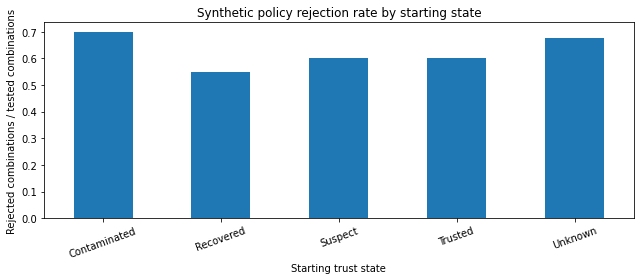

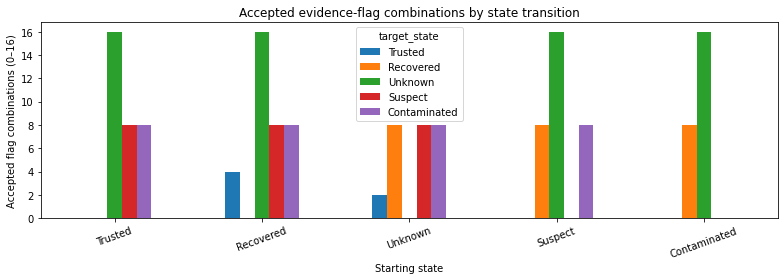

In [5]:
state_pair_summary = exhaustive_df.groupby(
    ["current_state","target_state"]
).agg(
    tested_flag_combinations=("accepted","size"),
    accepted_combinations=("accepted","sum"),
    rejected_combinations=("accepted", lambda s: int((~s).sum())),
    invariant_violations=("invariant_violation_count","sum")
).reset_index()
display(state_pair_summary)

acceptance_by_source = exhaustive_df.groupby("current_state").agg(
    accepted_cases=("accepted","sum"),
    total_cases=("accepted","size")
).reset_index()
acceptance_by_source["rejection_rate"] = 1 - acceptance_by_source["accepted_cases"] / acceptance_by_source["total_cases"]
display(acceptance_by_source)

ax = acceptance_by_source.plot(kind="bar", x="current_state", y="rejection_rate", legend=False, figsize=(9,4))
ax.set_title("Synthetic policy rejection rate by starting state")
ax.set_xlabel("Starting trust state")
ax.set_ylabel("Rejected combinations / tested combinations")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

pivot = state_pair_summary.pivot(index="current_state", columns="target_state", values="accepted_combinations").reindex(index=STATES, columns=STATES)
ax = pivot.plot(kind="bar", figsize=(11,4))
ax.set_title("Accepted evidence-flag combinations by state transition")
ax.set_xlabel("Starting state")
ax.set_ylabel("Accepted flag combinations (0–16)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
print("Plot counts describe this policy grid only, not real-world safety or state prevalence.")

## 6. Export audit artifacts

In [6]:
sequence_df.to_csv("trustsr_lab10_sequence_results.csv", index=False)
audit_df.to_csv("trustsr_lab10_transition_audit_log.csv", index=False)
exhaustive_df.to_csv("trustsr_lab10_exhaustive_policy_cases.csv", index=False)
state_pair_summary.to_csv("trustsr_lab10_state_pair_summary.csv", index=False)
acceptance_by_source.to_csv("trustsr_lab10_rejection_summary.csv", index=False)

exports = [
    "trustsr_lab10_sequence_results.csv",
    "trustsr_lab10_transition_audit_log.csv",
    "trustsr_lab10_exhaustive_policy_cases.csv",
    "trustsr_lab10_state_pair_summary.csv",
    "trustsr_lab10_rejection_summary.csv",
]
for name in exports:
    p = Path(name)
    assert p.exists() and p.stat().st_size > 0
    print("Created:", name, "| bytes:", p.stat().st_size)

assert audit_df["invariant_violations"].eq("").all()
assert exhaustive_df["invariant_violation_count"].eq(0).all()
print("Evidence classification: synthetic state-machine testing only.")

Created: trustsr_lab10_sequence_results.csv | bytes: 842
Created: trustsr_lab10_transition_audit_log.csv | bytes: 2823
Created: trustsr_lab10_exhaustive_policy_cases.csv | bytes: 44372
Created: trustsr_lab10_state_pair_summary.csv | bytes: 827
Created: trustsr_lab10_rejection_summary.csv | bytes: 156
Evidence classification: synthetic state-machine testing only.


## 7. Interpretation limits and publication wording

### What this lab supports
- The implementation's stated transition policy was tested over all 400 combinations of current state, target state, and four Boolean evidence flags.
- Five hand-authored multi-step sequences were checked.
- Rejected attempts were checked to ensure the current state did not change.
- Transition decisions and evidence flags were exported as an audit log.

### What this lab does not support
- A proof that the transition policy is optimal, complete for every threat model, or secure against arbitrary attacks.
- Reliability or authenticity of evidence flags, trusted snapshots, or independent verifiers in a real deployment.
- Empirical claims about real agent contamination, recovery success, or security effectiveness.

### Publication wording
“We tested a specified five-state trust-state policy using five synthetic transition sequences and exhaustive enumeration of 400 combinations of source state, target state, and evidence flags. Assertions checked selected transition invariants and state preservation after rejected attempts. These results establish implementation conformance to the encoded policy only, not real-world security effectiveness.”

### Completion checklist
1. Run all cells in a fresh Colab runtime.
2. Confirm 400 exhaustive cases and all assertions pass.
3. Confirm all five CSV exports are created.
4. Review the allowed transition policy with the threat model before treating it as final.
5. Keep all tables and plots labeled synthetic simulation.